In [1]:

import pandas as pd

url = "https://raw.githubusercontent.com/ankane/metro-traffic/master/data/Metro_Interstate_Traffic_Volume.csv"

try:
    df = pd.read_csv(url)
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())
except Exception as e:
    print("Could not load dataset:", e)


Could not load dataset: HTTP Error 404: Not Found


In [2]:

import pandas as pd

url = "https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip"

try:
    df = pd.read_csv(url, compression="zip")
    print("Dataset loaded successfully!")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())
except Exception as e:
    print("Error:", e)


Error: 'utf-8' codec can't decode byte 0x8b in position 1: invalid start byte


In [3]:

import os

print(os.listdir('/content'))



['.config', 'Metro_Interstate_Traffic_Volume.csv', 'sample_data']


In [4]:

import pandas as pd

df = pd.read_csv('/content/Metro_Interstate_Traffic_Volume.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Number of rows and columns: (48204, 9)

Column names:
['traffic_volume', 'holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time']

First 5 records:


,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time
0,5545,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,02-10-2012 09:00
1,4516,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,02-10-2012 10:00
2,4767,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 11:00
3,5026,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 12:00
4,4918,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,02-10-2012 13:00



Missing values:
traffic_volume             0
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
dtype: int64


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Convert date_time into datetime format
df['date_time'] = pd.to_datetime(
    df['date_time'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

# Remove invalid timestamps and sort chronologically
df = df.dropna(subset=['date_time', 'traffic_volume'])
df = df.sort_values('date_time')

# Remove duplicate timestamps
df = df.drop_duplicates(subset=['date_time'])

# Set timestamp as index
df = df.set_index('date_time')

# Select traffic and relevant weather features
data = df[['traffic_volume', 'temp', 'rain_1h',
           'snow_1h', 'clouds_all']].copy()

# Add time-based features
data['hour'] = data.index.hour
data['day_of_week'] = data.index.dayofweek

# Display results
print("Preprocessing completed successfully!")
print("Dataset shape:", data.shape)
print("Start time:", data.index.min())
print("End time:", data.index.max())
print("\nMissing values:")
print(data.isnull().sum())

display(data.head())


Preprocessing completed successfully!
Dataset shape: (40575, 7)
Start time: 2012-10-02 09:00:00
End time: 2018-09-30 23:00:00

Missing values:
traffic_volume    0
temp              0
rain_1h           0
snow_1h           0
clouds_all        0
hour              0
day_of_week       0
dtype: int64


,traffic_volume,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week
date_time,,,,,,,
2012-10-02 09:00:00,5545,288.28,0.0,0.0,40,9,1
2012-10-02 10:00:00,4516,289.36,0.0,0.0,75,10,1
2012-10-02 11:00:00,4767,289.58,0.0,0.0,90,11,1
2012-10-02 12:00:00,5026,290.13,0.0,0.0,90,12,1
2012-10-02 13:00:00,4918,291.14,0.0,0.0,75,13,1


In [7]:

# TASK 2: Generate sequential input-output windows

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Make the data continuous at hourly intervals
data = data.resample('h').mean()

# Fill missing hourly values using time interpolation
data = data.interpolate(method='time').ffill().bfill()

print("Hourly data shape:", data.shape)
print("Missing values:", data.isnull().sum().sum())

# Normalize the features
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# Use previous 24 hours to predict the next hour
sequence_length = 24
target_index = data.columns.get_loc('traffic_volume')

X = []
y = []
target_positions = []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i, target_index])
    target_positions.append(i)

X = np.array(X)
y = np.array(y)
target_positions = np.array(target_positions)

# Split chronologically: first 80% for training, last 20% for testing
split_point = int(len(data) * 0.80)

train_mask = target_positions < split_point
test_mask = target_positions >= split_point

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("\nSequential windows created successfully!")
print("X shape:", X.shape)
print("Training input:", X_train.shape)
print("Training output:", y_train.shape)
print("Testing input:", X_test.shape)
print("Testing output:", y_test.shape)


Hourly data shape: (52551, 7)
Missing values: 0

Sequential windows created successfully!
X shape: (52527, 24, 7)
Training input: (42016, 24, 7)
Training output: (42016,)
Testing input: (10511, 24, 7)
Testing output: (10511,)


In [8]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Split point based on chronological order
split_point = int(len(data) * 0.80)

# Fit scaler only on training-period data
scaler = MinMaxScaler()
scaler.fit(data.iloc[:split_point])

# Transform all records using training-period scaling
scaled_data = scaler.transform(data)

# Create 24-hour input windows and next-hour targets
sequence_length = 24
target_index = data.columns.get_loc('traffic_volume')

X, y, target_positions = [], [], []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i, target_index])
    target_positions.append(i)

X = np.array(X)
y = np.array(y)
target_positions = np.array(target_positions)

train_mask = target_positions < split_point
test_mask = target_positions >= split_point

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training input:", X_train.shape)
print("Training output:", y_train.shape)
print("Testing input:", X_test.shape)
print("Testing output:", y_test.shape)


Training input: (42016, 24, 7)
Training output: (42016,)
Testing input: (10511, 24, 7)
Testing output: (10511,)


In [9]:

# TASK 3: Build and train the LSTM model

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

# Create LSTM architecture
model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Stop if validation performance stops improving
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("\nLSTM training completed!")
model.summary()


Epoch 1/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - loss: 0.0239 - mae: 0.1079 - val_loss: 0.0081 - val_mae: 0.0626
Epoch 2/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - loss: 0.0089 - mae: 0.0649 - val_loss: 0.0059 - val_mae: 0.0547
Epoch 3/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 19s 31ms/step - loss: 0.0063 - mae: 0.0549 - val_loss: 0.0048 - val_mae: 0.0484
Epoch 4/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 23s 36ms/step - loss: 0.0052 - mae: 0.0493 - val_loss: 0.0041 - val_mae: 0.0463
Epoch 5/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - loss: 0.0042 - mae: 0.0450 - val_loss: 0.0038 - val_mae: 0.0450
Epoch 6/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - loss: 0.0037 - mae: 0.0424 - val_loss: 0.0032 - val_mae: 0.0421
Epoch 7/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 41s 35ms/step - loss: 0.0033 - mae: 0.0399 - val_loss: 0.0031 - val_mae: 0.0409
Epoch 8/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - loss: 0.0030 - mae: 0.0383 - val_loss: 0.0029 - val_mae: 0.0403
Epoch 9/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 

KeyboardInterrupt: 

In [10]:

# Faster LSTM model for hourly traffic prediction

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(32),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=256,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training completed!")


Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - loss: 0.0677 - mae: 0.2092 - val_loss: 0.0314 - val_mae: 0.1424
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0172 - mae: 0.0996 - val_loss: 0.0136 - val_mae: 0.0844
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0135 - mae: 0.0877 - val_loss: 0.0132 - val_mae: 0.0868
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - loss: 0.0091 - mae: 0.0711 - val_loss: 0.0095 - val_mae: 0.0732
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0068 - mae: 0.0607 - val_loss: 0.0077 - val_mae: 0.0668
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0055 - mae: 0.0537 - val_loss: 0.0062 - val_mae: 0.0598
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.0047 - mae: 0.0505 - val_loss: 0.0050 - val_mae: 0.0528
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0042 - mae: 0.0477 - val_loss: 0.0042 - val_mae: 0.0477
Epoch 9/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/

In [11]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict traffic volume using test data
y_pred_scaled = model.predict(X_test, verbose=0)

# Convert predictions back to original traffic-volume scale
target_index = data.columns.get_loc('traffic_volume')

y_actual = scaler.inverse_transform(
    np.column_stack([
        y_test if i == target_index else np.zeros(len(y_test))
        for i in range(data.shape[1])
    ])
)[:, target_index]

y_predicted = scaler.inverse_transform(
    np.column_stack([
        y_pred_scaled.flatten() if i == target_index
        else np.zeros(len(y_pred_scaled))
        for i in range(data.shape[1])
    ])
)[:, target_index]

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")


Mean Absolute Error (MAE): 302.1406
Root Mean Squared Error (RMSE): 408.6177


In [12]:

average_traffic = np.mean(y_actual)
mae_percentage = (mae / average_traffic) * 100

print(f"Average actual traffic: {average_traffic:.2f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE as percentage of average traffic: {mae_percentage:.2f}%")


Average actual traffic: 3344.92
MAE: 302.1406
RMSE: 408.6177
MAE as percentage of average traffic: 9.03%


In [13]:

import tensorflow as tf
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(42)

# Use the previous 48 hours to predict the next hour
sequence_length = 48
target_index = data.columns.get_loc('traffic_volume')

X, y, target_positions = [], [], []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i, target_index])
    target_positions.append(i)

X = np.array(X)
y = np.array(y)
target_positions = np.array(target_positions)

split_point = int(len(data) * 0.80)
train_mask = target_positions < split_point
test_mask = target_positions >= split_point

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='mse',
    metrics=['mae']
)

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=0.00001
    )
]

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=256,
    validation_split=0.1,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

print("Improved LSTM training completed!")


Epoch 1/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step - loss: 0.0684 - mae: 0.2173 - val_loss: 0.0563 - val_mae: 0.2047 - learning_rate: 5.0000e-04
Epoch 2/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 26s 177ms/step - loss: 0.0258 - mae: 0.1222 - val_loss: 0.0164 - val_mae: 0.0924 - learning_rate: 5.0000e-04
Epoch 3/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 41s 177ms/step - loss: 0.0129 - mae: 0.0805 - val_loss: 0.0092 - val_mae: 0.0652 - learning_rate: 5.0000e-04
Epoch 4/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 26s 175ms/step - loss: 0.0102 - mae: 0.0706 - val_loss: 0.0071 - val_mae: 0.0586 - learning_rate: 5.0000e-04
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 26s 173ms/step - loss: 0.0091 - mae: 0.0661 - val_loss: 0.0063 - val_mae: 0.0543 - learning_rate: 5.0000e-04
Epoch 6/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 26s 173ms/step - loss: 0.0085 - mae: 0.0634 - val_loss: 0.0056 - val_mae: 0.0506 - learning_rate: 5.0000e-04
Epoch 7/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 42s 178ms/step - loss: 0.0078 - mae: 0.0601 - val_loss: 0.0051 - v

In [14]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict using the improved model
y_pred_scaled = model.predict(X_test, verbose=0).ravel()

target_index = data.columns.get_loc('traffic_volume')

# Convert actual values back to vehicle counts
actual_array = np.zeros((len(y_test), data.shape[1]))
actual_array[:, target_index] = y_test

y_actual = scaler.inverse_transform(actual_array)[:, target_index]

# Convert predicted values back to vehicle counts
pred_array = np.zeros((len(y_pred_scaled), data.shape[1]))
pred_array[:, target_index] = y_pred_scaled

y_predicted = scaler.inverse_transform(pred_array)[:, target_index]

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print("IMPROVED LSTM TEST RESULTS")
print(f"MAE: {mae:.4f} vehicles/hour")
print(f"RMSE: {rmse:.4f} vehicles/hour")
print(f"Average actual traffic: {np.mean(y_actual):.2f}")
print(f"Relative MAE: {mae / np.mean(y_actual) * 100:.2f}%")


IMPROVED LSTM TEST RESULTS
MAE: 280.1809 vehicles/hour
RMSE: 417.1488 vehicles/hour
Average actual traffic: 3344.92
Relative MAE: 8.38%


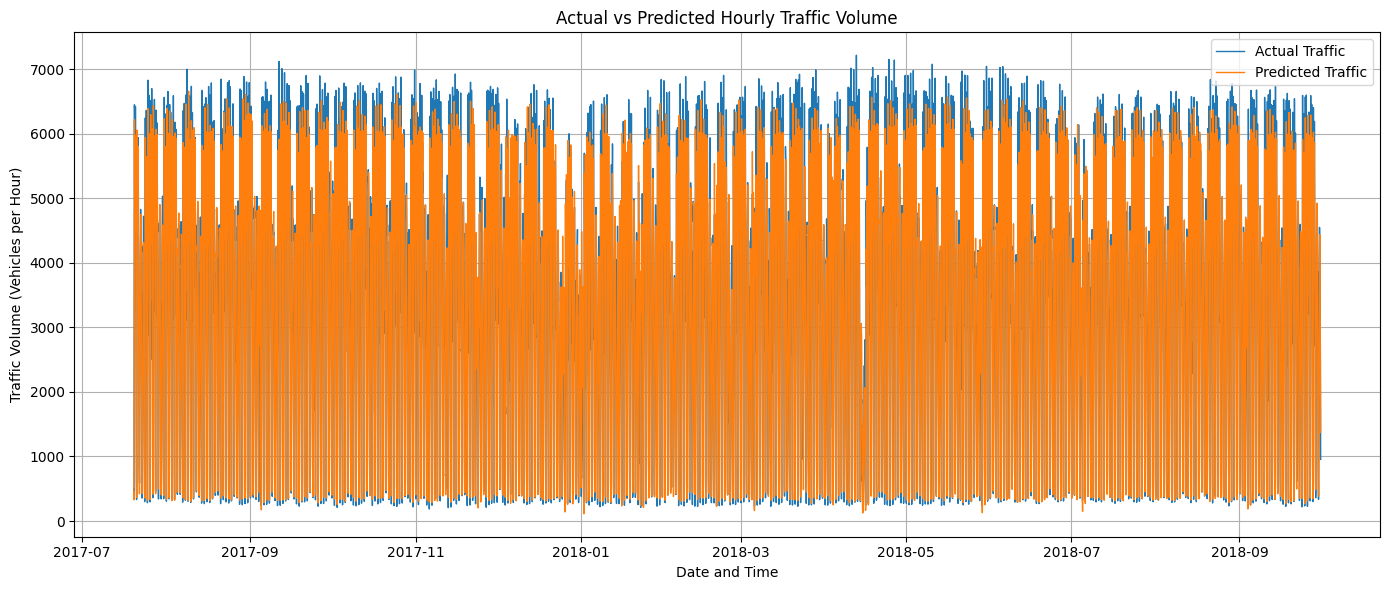

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Get timestamps for the test data
split_point = int(len(data) * 0.80)
test_positions = np.arange(48, len(data))
test_positions = test_positions[test_positions >= split_point]
test_times = data.index[test_positions]

# Plot actual and predicted traffic
plt.figure(figsize=(14, 6))

plt.plot(test_times, y_actual,
         label='Actual Traffic', linewidth=1)

plt.plot(test_times, y_predicted,
         label='Predicted Traffic', linewidth=1)

plt.title('Actual vs Predicted Hourly Traffic Volume')
plt.xlabel('Date and Time')
plt.ylabel('Traffic Volume (Vehicles per Hour)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Top 5 Predicted Peak Traffic Hours:
Hour
16    5484.193685
17    5320.283312
15    5276.935305
14    5011.055274
7     4919.869025
Name: Predicted_Traffic, dtype: float64


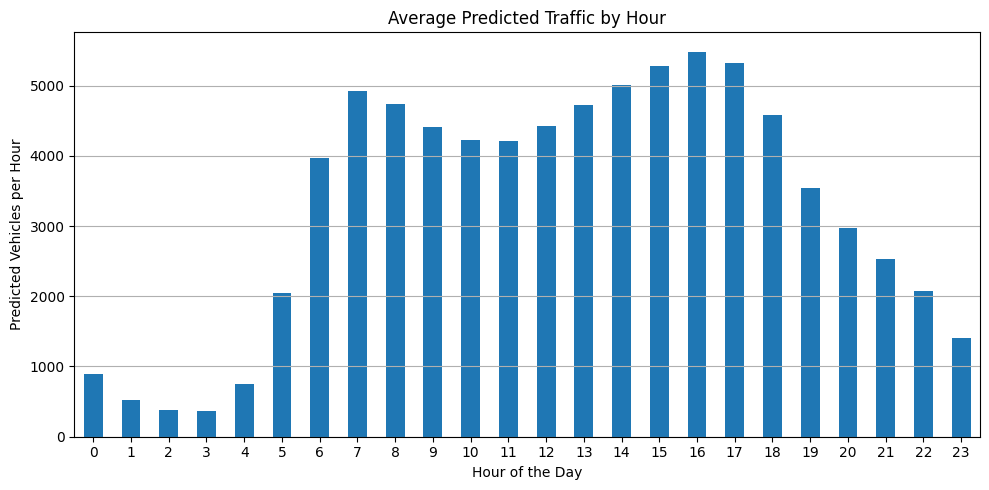

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a table using actual and predicted traffic
results = pd.DataFrame({
    'Date_Time': test_times,
    'Actual_Traffic': y_actual.flatten(),
    'Predicted_Traffic': y_predicted.flatten()
})

# Extract the hour from each timestamp
results['Hour'] = results['Date_Time'].dt.hour

# Calculate average predicted traffic for each hour
hourly_traffic = results.groupby('Hour')['Predicted_Traffic'].mean()

# Display the top 5 peak traffic hours
peak_hours = hourly_traffic.sort_values(ascending=False).head(5)

print("Top 5 Predicted Peak Traffic Hours:")
print(peak_hours)

# Plot predicted traffic by hour
plt.figure(figsize=(10, 5))
hourly_traffic.plot(kind='bar')
plt.title('Average Predicted Traffic by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Predicted Vehicles per Hour')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()